# 인공지능기초 7주차 실습 — 깊은 신경망, 어떻게 잘 배우게 할까? (Keras 버전)

**목표:** 강의에서 배운 세 가지 도구를 직접 돌려 보고, 학습 로그만 보고 문제를 진단한다.

| 실습 | 내용 | 시간 |
|---|---|---|
| 0 | 준비: 데이터와 도구 | 2분 |
| 1 | 기울기 소실: 시그모이드 vs ReLU+He | 7분 |
| 2 | 최적화: 좁은 골짜기에서 SGD·모멘텀·RMSprop·Adam 경주 | 6분 |
| 3 | 과적합: L2·드롭아웃·조기 종료 비교 | 7분 |
| 4 | 디버깅 튜터: 수상한 학습 로그 진단하기 | 3분 |

Colab에서 **런타임 → 모두 실행**으로 돌리면 CPU만으로 몇 분 안에 끝납니다. (Keras 3, TensorFlow 백엔드)

## 실습 0. 준비 (2분)
손글씨 숫자 데이터(8×8 이미지, 1,797장, 0~9)를 씁니다. 작아서 CPU로도 몇 초면 학습됩니다.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

keras.utils.set_random_seed(0)

X, y = load_digits(return_X_y=True)
X = (X / 16.0).astype("float32")                  # 픽셀 값을 0~1로
Xtr, Xva, ytr, yva = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
print("훈련:", Xtr.shape, " 검증:", Xva.shape)

loss_fn = keras.losses.SparseCategoricalCrossentropy(from_logits=True)

INITS = {
    "small":  lambda n_in: keras.initializers.RandomUniform(-1 / np.sqrt(n_in), 1 / np.sqrt(n_in)),  # 작은 균등분포
    "xavier": lambda n_in: keras.initializers.GlorotNormal(),   # 시그모이드·tanh 계열: Var(w) = 2 / (n_in + n_out)
    "he":     lambda n_in: keras.initializers.HeNormal(),       # ReLU 계열: Var(w) = 2 / n_in
}


def make_mlp(depth=10, width=64, act="sigmoid", init="small", p_drop=0.0, l2=0.0):
    """depth개의 은닉층을 가진 다층 퍼셉트론(MLP)을 만든다."""
    model = keras.Sequential([keras.Input(shape=(64,))])
    n_in = 64
    for _ in range(depth):
        model.add(layers.Dense(
            width, activation=act,
            kernel_initializer=INITS[init](n_in),
            kernel_regularizer=keras.regularizers.L2(l2) if l2 > 0 else None))  # L2: 손실에 λ·Σw² 추가
        if p_drop > 0:
            model.add(layers.Dropout(p_drop))
        n_in = width
    model.add(layers.Dense(10))                       # 출력: 10개 클래스 점수(logit)
    return model


class EpochLogger(keras.callbacks.Callback):
    """에폭이 끝날 때마다 (드롭아웃을 끈 상태로) 훈련/검증 손실, 검증 정확도, 첫 층 기울기 크기를 잰다.
    Keras가 history에 남기는 loss에는 L2 벌점이 섞이고 드롭아웃이 켜져 있어서, 비교용 값은 따로 계산한다."""
    def __init__(self, Xt, yt):
        super().__init__()
        self.Xt, self.yt = Xt, yt
        self.hist = {"train": [], "val": [], "acc": [], "g_first": []}

    def on_epoch_end(self, epoch, logs=None):
        first = self.model.layers[0]
        with tf.GradientTape() as tape:
            tl = loss_fn(self.yt, self.model(self.Xt, training=False))
        g = tape.gradient(tl, first.kernel)
        out = self.model(Xva, training=False)
        vl = loss_fn(yva, out)
        acc = np.mean(np.argmax(out, axis=1) == yva)
        for k, v in zip(self.hist, (tl, vl, acc, tf.norm(g))):
            self.hist[k].append(float(v))


def train(model, opt, epochs=30, batch=64, Xt=Xtr, yt=ytr, patience=None):
    """학습하면서 에폭마다 훈련/검증 손실, 검증 정확도, 첫 층 기울기 크기를 기록한다."""
    model.compile(optimizer=opt, loss=loss_fn)
    log = EpochLogger(Xt, yt)
    cbs = [log]
    if patience is not None:                          # 조기 종료: 가장 좋았던 에폭의 가중치로 복원
        cbs.append(keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience,
                                                 restore_best_weights=True))
    model.fit(Xt, yt, validation_data=(Xva, yva), epochs=epochs, batch_size=batch,
              shuffle=True, verbose=0, callbacks=cbs)
    hist = log.hist
    if patience is not None and len(hist["val"]) < epochs:
        hist["best_ep"] = int(np.argmin(hist["val"]))
        print(f"  ⏹ 에폭 {len(hist['val'])}에서 중단 → 최저 검증 손실 에폭 {hist['best_ep']+1}의 가중치로 복원")
    return hist

훈련: (1257, 64)  검증: (540, 64)


## 실습 1. 기울기 소실 (7분)
은닉층 10개짜리 신경망을 두 가지로 만들고, **학습 전 첫 번째 역전파**에서 층별 기울기 크기를 잽니다.
- A: 시그모이드 + 작은 균등분포 초기화
- B: ReLU + He 초기화

🔎 **예측 먼저:** 입력 쪽 층(1층)의 기울기는 출력 쪽 층(10층)의 몇 분의 1일까요?

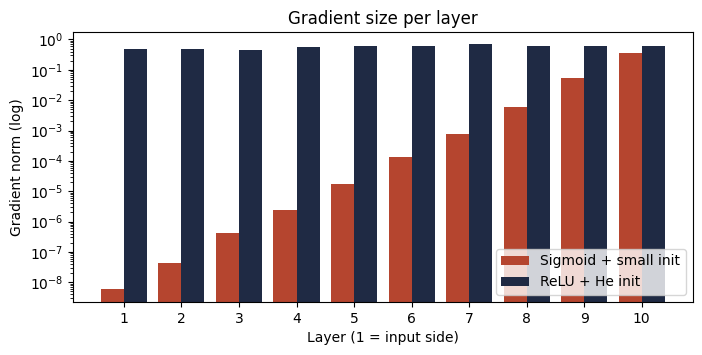

시그모이드: 1층/10층 = 1.6e-08
ReLU+He  : 1층/10층 = 0.78


In [2]:
def layer_grad_norms(model):
    dense = [l for l in model.layers if isinstance(l, layers.Dense)][:-1]   # 출력층 제외
    with tf.GradientTape() as tape:
        loss = loss_fn(ytr, model(Xtr, training=False))
    grads = tape.gradient(loss, [l.kernel for l in dense])
    return [float(tf.norm(g)) for g in grads]

keras.utils.set_random_seed(0)
g_sig  = layer_grad_norms(make_mlp(act="sigmoid", init="small"))
keras.utils.set_random_seed(0)
g_relu = layer_grad_norms(make_mlp(act="relu", init="he"))

ls = np.arange(1, 11)
plt.figure(figsize=(8, 3.5))
plt.bar(ls - 0.2, g_sig,  width=0.4, label="Sigmoid + small init", color="#b5452f")
plt.bar(ls + 0.2, g_relu, width=0.4, label="ReLU + He init", color="#1f2a44")
plt.yscale("log"); plt.xticks(ls); plt.xlabel("Layer (1 = input side)")
plt.ylabel("Gradient norm (log)"); plt.legend(loc="lower right"); plt.title("Gradient size per layer")
plt.show()

print(f"시그모이드: 1층/10층 = {g_sig[0]/g_sig[-1]:.1e}")
print(f"ReLU+He  : 1층/10층 = {g_relu[0]/g_relu[-1]:.2f}")

이제 두 신경망을 **같은 SGD(학습률 0.05)로 30에폭** 학습시켜 봅니다.

Sigmoid + small    최종 검증 정확도 = 0.102
ReLU + He          최종 검증 정확도 = 0.957


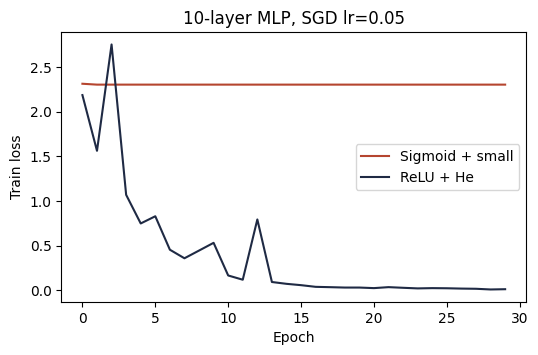

In [3]:
results = {}
for name, act, init in [("Sigmoid + small", "sigmoid", "small"), ("ReLU + He", "relu", "he")]:
    keras.utils.set_random_seed(0)
    m = make_mlp(act=act, init=init)
    results[name] = train(m, keras.optimizers.SGD(learning_rate=0.05), epochs=30)
    print(f"{name:18s} 최종 검증 정확도 = {results[name]['acc'][-1]:.3f}")

plt.figure(figsize=(6, 3.5))
for (name, h), c in zip(results.items(), ["#b5452f", "#1f2a44"]):
    plt.plot(h["train"], label=name, color=c)
plt.xlabel("Epoch"); plt.ylabel("Train loss"); plt.legend(); plt.title("10-layer MLP, SGD lr=0.05")
plt.show()

**✏️ 해 보기**
1. 시그모이드의 손실이 2.30 근처에서 멈춰 있습니다. 2.30 = ln(10)은 무슨 뜻일까요? (힌트: 10개 클래스를 모두 같은 확률로 찍는 경우)
2. `act="sigmoid", init="xavier"`로 바꾸면 기울기 그래프가 어떻게 변하나요? 층 수를 `depth=3`으로 줄이면요?
3. 참고: Keras `Dense`의 기본 초기화는 Xavier(`glorot_uniform`)입니다. 시그모이드에서는 그것만으로 충분할까요?

## 실습 2. 최적화: 좁고 긴 골짜기 경주 (6분)
손실 함수 $L(w_1, w_2) = 0.05\,w_1^2 + 2\,w_2^2$ 는 **가로로 길고 세로로 가파른 골짜기**입니다(최저점 = 원점).
네 가지 최적화 방법이 같은 출발점에서 40걸음 동안 어디까지 가는지 비교합니다.

SGD       40걸음 후 위치 = ( -1.43,   0.00),  손실 = 0.1018
Momentum  40걸음 후 위치 = (  0.99,   0.02),  손실 = 0.0501
RMSprop   40걸음 후 위치 = ( -0.15,  -0.00),  손실 = 0.0011
Adam      40걸음 후 위치 = (  0.02,  -0.11),  손실 = 0.0223


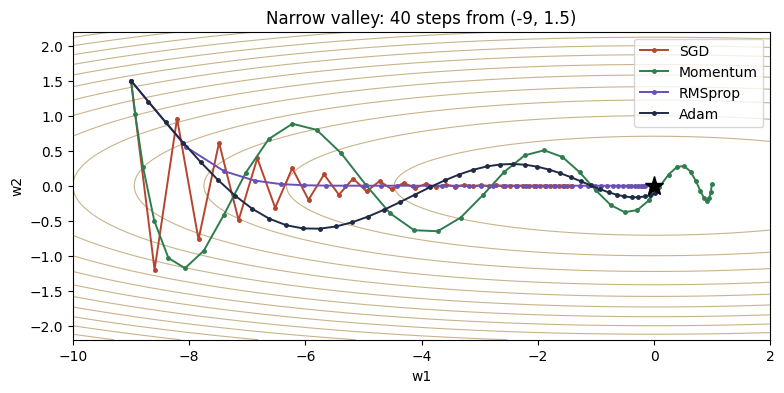

In [4]:
def valley(w):
    return 0.05 * w[0] ** 2 + 2.0 * w[1] ** 2

def run_path(opt_name, steps=40, start=(-9.0, 1.5)):
    w = keras.Variable(np.array(start, dtype="float32"))
    opt = {
        "SGD":      keras.optimizers.SGD(learning_rate=0.45),
        "Momentum": keras.optimizers.SGD(learning_rate=0.08, momentum=0.9),
        "RMSprop":  keras.optimizers.RMSprop(learning_rate=0.3, rho=0.9),
        "Adam":     keras.optimizers.Adam(learning_rate=0.3),
    }[opt_name]
    path = [w.numpy().copy()]
    for _ in range(steps):
        with tf.GradientTape() as tape:
            loss = valley(w)
        g = tape.gradient(loss, w.value)
        opt.apply_gradients([(g, w)])
        path.append(w.numpy().copy())
    return np.array(path)

g1, g2 = np.meshgrid(np.linspace(-10, 2, 200), np.linspace(-2.2, 2.2, 200))
plt.figure(figsize=(9, 4))
plt.contour(g1, g2, 0.05 * g1**2 + 2 * g2**2, levels=15, colors="#c9b48a", linewidths=0.8)
colors = {"SGD": "#b5452f", "Momentum": "#2f7d4f", "RMSprop": "#6a4fb5", "Adam": "#1f2a44"}
for name in colors:
    p = run_path(name)
    plt.plot(p[:, 0], p[:, 1], "-o", ms=2.5, lw=1.4, color=colors[name], label=name)
    print(f"{name:9s} 40걸음 후 위치 = ({p[-1,0]:6.2f}, {p[-1,1]:6.2f}),  손실 = {valley(p[-1]):.4f}")
plt.plot(0, 0, "k*", ms=14)
plt.legend(); plt.title("Narrow valley: 40 steps from (-9, 1.5)"); plt.xlabel("w1"); plt.ylabel("w2")
plt.show()

**✏️ 해 보기**
1. SGD의 학습률을 0.45 → **0.55**로 올려 보세요. 무슨 일이 생기나요? (세로 방향 경사가 가팔라 보폭 한계가 있습니다)
2. 모멘텀의 `momentum=0.9`를 **0.0**으로 바꾸면 SGD와 무엇이 같아지나요?
3. 모멘텀이 원점을 지나쳤다가 되돌아오는 이유는? 굴러가는 공의 관성으로 설명해 보세요.

## 실습 3. 과적합과 규제화 (7분)
일부러 "외우기 쉬운" 상황을 만듭니다.
- 훈련 자료는 **200장만**, 그중 **20%는 정답 라벨을 무작위로 틀리게** 바꿉니다 (현실의 라벨링 실수).
- 큰 신경망(은닉층 2개 × 512)을 150에폭 학습 → 틀린 라벨까지 **외우면** 검증 손실이 올라갑니다.

네 가지 설정을 비교합니다: 규제 없음 / L2 / 드롭아웃 / 조기 종료

훈련 200장 중 라벨을 흔든 자료: 32장
No regularization
L2 (lambda=0.005)
Dropout (p=0.5)
Early stopping
  ⏹ 에폭 16에서 중단 → 최저 검증 손실 에폭 6의 가중치로 복원


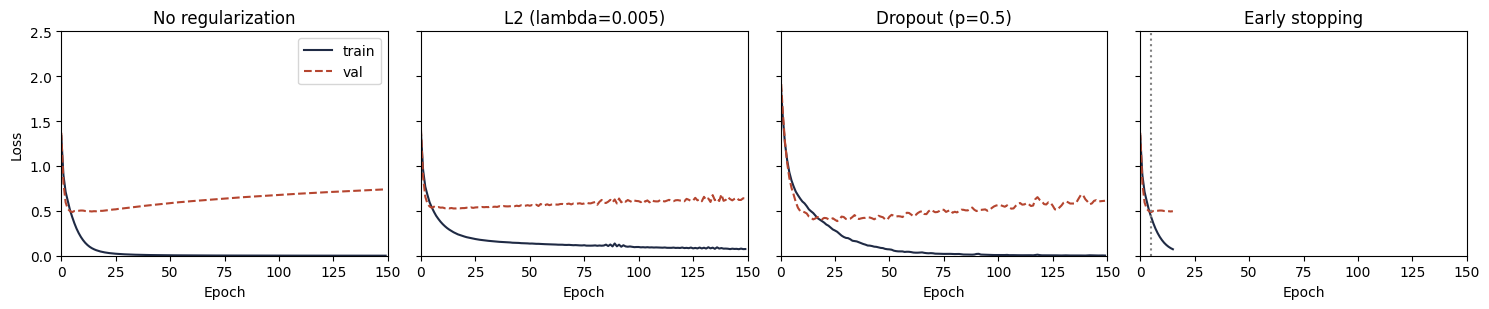


설정                       훈련손실     검증손실    검증정확도
No regularization       0.000    0.740    0.828
L2 (lambda=0.005)       0.075    0.638    0.800
Dropout (p=0.5)         0.002    0.612    0.831
Early stopping          0.433    0.486    0.874


In [5]:
n_small, noise = 200, 0.2
rng = np.random.default_rng(1)
Xs, ys = Xtr[:n_small], ytr[:n_small].copy()
flip = rng.random(n_small) < noise
ys[flip] = rng.integers(0, 10, flip.sum())
print(f"훈련 {n_small}장 중 라벨을 흔든 자료: {flip.sum()}장")

configs = {
    "No regularization": dict(p_drop=0.0, l2=0.0,   patience=None),
    "L2 (lambda=0.005)": dict(p_drop=0.0, l2=0.005, patience=None),
    "Dropout (p=0.5)":   dict(p_drop=0.5, l2=0.0,   patience=None),
    "Early stopping":    dict(p_drop=0.0, l2=0.0,   patience=10),
}
reg = {}
for name, c in configs.items():
    keras.utils.set_random_seed(0)
    m = make_mlp(depth=2, width=512, act="relu", init="he", p_drop=c["p_drop"], l2=c["l2"])
    print(name)
    reg[name] = train(m, keras.optimizers.Adam(learning_rate=1e-3), epochs=150, batch=32,
                      Xt=Xs, yt=ys, patience=c["patience"])

fig, axes = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
for ax, (name, h) in zip(axes, reg.items()):
    ax.plot(h["train"], color="#1f2a44", label="train")
    ax.plot(h["val"], "--", color="#b5452f", label="val")
    if "best_ep" in h:
        ax.axvline(h["best_ep"], color="gray", ls=":")
    ax.set_title(name); ax.set_xlabel("Epoch"); ax.set_ylim(0, 2.5); ax.set_xlim(0, 150)
axes[0].set_ylabel("Loss"); axes[0].legend()
plt.tight_layout(); plt.show()

print(f"\n{'설정':20s} {'훈련손실':>8s} {'검증손실':>8s} {'검증정확도':>8s}")
for name, h in reg.items():
    k = h.get("best_ep", -1)          # 조기 종료는 복원한 에폭의 값으로 비교
    print(f"{name:20s} {h['train'][k]:8.3f} {h['val'][k]:8.3f} {h['acc'][k]:8.3f}")

> 참고: 여기 그린 손실은 드롭아웃을 끄고 L2 벌점을 뺀 **순수 교차 엔트로피**입니다. Keras `fit()`이 history에 남기는 `loss`에는 L2 벌점 λ·Σw²가 더해져 있어 그대로 비교하면 L2가 불리해 보입니다.

**✏️ 해 보기**
1. "규제 없음"에서 검증 손실이 가장 낮았던 에폭은? 그 뒤에 검증 **정확도**도 떨어지나요? (손실과 정확도는 다르게 움직일 수 있습니다)
2. `noise = 0.0`으로 라벨을 깨끗하게 하면 네 설정의 차이는 어떻게 되나요?
3. `n_small = 1000`으로 자료를 늘리면 과적합은 어떻게 되나요? — **자료를 늘리는 것이 가장 강력한 규제**입니다.

## 실습 4. 디버깅 튜터 (3분 + 과제)
아래 셀은 정체를 숨긴 학습 4개(A~D)의 로그를 출력합니다.
1. 로그 하나를 복사해 생성형 AI에게 보여 주고 **"이 학습의 문제와 처방은?"**이라고 물어보세요.
2. AI의 진단을 강의 마지막 장의 **증상–원인–처방 표**와 비교해 직접 검증하세요.
3. 처방을 코드에 한 줄로 적용해 다시 돌리고, 정말 고쳐지는지 확인하세요. (과제)

In [6]:
def mystery(code):
    keras.utils.set_random_seed(0)
    if code == "A":
        m = make_mlp(depth=2, width=512, act="relu", init="he")
        return train(m, keras.optimizers.Adam(learning_rate=1e-3), epochs=60, batch=32, Xt=Xs, yt=ys)
    if code == "B":
        m = make_mlp(depth=10, act="sigmoid", init="small")
        return train(m, keras.optimizers.SGD(learning_rate=0.1), epochs=20)
    if code == "C":
        m = make_mlp(depth=4, act="relu", init="he")
        return train(m, keras.optimizers.SGD(learning_rate=1.5), epochs=20)
    if code == "D":
        m = make_mlp(depth=4, act="relu", init="he")
        return train(m, keras.optimizers.SGD(learning_rate=0.01), epochs=20)

def print_log(code, h, every=None):
    every = every or max(1, len(h["train"]) // 10)
    print(f"===== 학습 로그 {code} =====")
    print(f"{'epoch':>5s} {'train_loss':>11s} {'val_loss':>9s} {'val_acc':>8s} {'grad(1층)':>11s}")
    for i in range(0, len(h["train"]), every):
        print(f"{i+1:5d} {h['train'][i]:11.4f} {h['val'][i]:9.4f} {h['acc'][i]:8.3f} {h['g_first'][i]:11.2e}")
    print()

for code in "ABCD":
    print_log(code, mystery(code))

===== 학습 로그 A =====
epoch  train_loss  val_loss  val_acc    grad(1층)
    1      1.3344    1.3694    0.646    3.79e-01
    7      0.3632    0.4978    0.872    1.01e-01
   13      0.1199    0.4974    0.841    5.46e-02
   19      0.0470    0.4991    0.830    2.81e-02
   25      0.0242    0.5151    0.833    1.73e-02
   31      0.0147    0.5324    0.835    1.01e-02
   37      0.0098    0.5503    0.835    7.56e-03
   43      0.0070    0.5657    0.835    5.93e-03
   49      0.0053    0.5808    0.831    5.02e-03
   55      0.0041    0.5959    0.830    3.84e-03

===== 학습 로그 B =====
epoch  train_loss  val_loss  val_acc    grad(1층)
    1      2.3068    2.3068    0.100    2.81e-09
    3      2.3073    2.3073    0.102    2.82e-09
    5      2.3072    2.3072    0.102    2.82e-09
    7      2.3072    2.3072    0.102    2.82e-09
    9      2.3071    2.3071    0.102    2.81e-09
   11      2.3071    2.3071    0.102    2.81e-09
   13      2.3070    2.3070    0.102    2.81e-09
   15      2.3070    2.3070 

## STEP 1. 로그 A에 대한 AI의 진단
- 진단: 과적합 (overfitting)
- epoch 7~13 근처에서 일반화가 최고점을 찍고, 이후에는 train만 계속 좋아지는 전형적인 패턴입니다.
1. train_loss는 1.3344 → 0.0041로 끝까지 단조 감소하는데, val_loss는 epoch 13의 0.4974를 바닥으로 0.5959(epoch 55)까지 계속 상승합니다. 두 곡선이 반대 방향으로 갈라지는 것이 핵심 신호입니다.
2. val_acc 최고점은 epoch 7의 0.872입니다. 이후 epoch 13에서 0.841로 떨어지고 0.83대에 머뭅니다. 최고점 대비 약 4%p 손해입니다.
3. epoch 19 이후 val_acc는 0.830~0.835로 사실상 고정인데 val_loss만 계속 오릅니다. 정확도는 그대로인데 loss가 오른다는 건 틀린 샘플에 대한 확신(confidence)이 커지고 있다는 뜻입니다. 즉 모델이 훈련 데이터를 외우면서 과신하는 상태입니다.

### 배제할 수 있는 것
- 기울기 소실/학습 정체는 아닙니다. grad(1층)가 0.379 → 0.005로 줄지만, 이는 train_loss가 0에 수렴하면서 줄 것이 없어진 결과로 보는 게 자연스럽습니다. 학습 초기에 val_acc가 0.646 → 0.872로 정상적으로 올랐으므로 1층까지 학습 신호가 전달되고 있었습니다.
- underfitting도 아닙니다. train_loss가 0.004까지 내려갔습니다.

### 처방 (우선순위 순)
1. Early stopping + 최적 체크포인트 저장: val_loss나 val_acc 기준으로 patience 3~5회 정도를 두고, 가장 좋은 시점의 가중치를 복원합니다. 이 로그라면 epoch 7~13 구간이 후보입니다.
2. 정규화 강화: weight decay(L2), dropout, 데이터 증강(데이터 종류에 맞게)을 적용합니다.
3. Label smoothing: 과신 문제(val_acc 고정 + val_loss 상승)를 직접 겨냥하는 방법입니다.
4. 모델 용량 축소 또는 데이터 추가: train이 0.004까지 내려가는 건 모델이 데이터에 비해 과하다는 신호입니다.
5. 학습률 스케줄링: 초반에 빠르게 수렴한 뒤 오래 끌 필요가 없으므로, 감쇠 스케줄과 early stopping을 함께 쓰면 좋습니다.

### 추가 확인
- 로그가 6 epoch 간격이라, 실제 최적점은 epoch 7~13 사이 어딘가일 수 있습니다. 매 epoch 기록으로 다시 확인해 보세요.
- val_acc 0.872와 0.830의 차이가 유의미한지는 검증셋 크기에 달려 있습니다. 검증셋이 작으면 흔들림일 수 있으니 크기를 확인하세요.
- 검증셋으로 early stopping 시점이나 하이퍼파라미터를 고르면 그 val 점수는 낙관적으로 편향됩니다. 최종 성능은 별도 test set으로 보고하는 것이 안전합니다.

## STEP 2. 검증하기
### 증상-원인-처방 표
- | 로그 | 로그 속 근거 | 원인 | 처방 |
- | A | 훈련 손실 1.46 -> 0.004, 검증 손실은 13에폭 0.49가 최저, 이후 0.61까지 상승 | 과적합 | p_drop=0.5 또는 patience=10 |

### AI의 진단
- 원인 : 과적합
- 로그 속 근거 : train_loss는 1.3344 → 0.0041로 끝까지 단조 감소하는데, val_loss는 epoch 13의 0.4974를 바닥으로 0.5959(epoch 55)까지 계속 상승합니다. 두 곡선이 반대 방향으로 갈라지는 것이 핵심 신호입니다.

### 결론
- 자료 속 표와 AI의 진단이 동일함.

## STEP 3. 고치기

In [ ]:
def mystery(code):
    keras.utils.set_random_seed(0)
    if code == "A":
        m = make_mlp(depth=2, width=512, act="relu", init="he", p_drop=0.5) # p_drop 인자에 0.5 부여
        return train(m, keras.optimizers.Adam(learning_rate=1e-3), epochs=60, batch=32, Xt=Xs, yt=ys)

def print_log(code, h, every=None):
    every = every or max(1, len(h["train"]) // 10)
    print(f"===== 학습 로그 {code} =====")
    print(f"{'epoch':>5s} {'train_loss':>11s} {'val_loss':>9s} {'val_acc':>8s} {'grad(1층)':>11s}")
    for i in range(0, len(h["train"]), every):
        print(f"{i+1:5d} {h['train'][i]:11.4f} {h['val'][i]:9.4f} {h['acc'][i]:8.3f} {h['g_first'][i]:11.2e}")
    print()


print_log("A", mystery("A"))

===== 학습 로그 A =====
epoch  train_loss  val_loss  val_acc    grad(1층)
    1      1.9439    2.0346    0.302    4.25e-01
    7      0.7718    0.6804    0.839    1.96e-01
   13      0.5526    0.4711    0.883    1.58e-01
   19      0.4022    0.4207    0.887    1.49e-01
   25      0.2928    0.4169    0.881    1.37e-01
   31      0.1987    0.4100    0.883    1.25e-01
   37      0.1498    0.4089    0.863    1.32e-01
   43      0.1077    0.4171    0.869    1.43e-01
   49      0.0762    0.4061    0.870    1.16e-01
   55      0.0486    0.4404    0.861    6.79e-02



In [12]:
def homework(act="sigmoid", init="small", p_drop=0.0, l2=0.0, patience=None):
    keras.utils.set_random_seed(0)
    m = make_mlp(depth=6, width=256, act=act, init=init, p_drop=p_drop, l2=l2)
    return train(m, keras.optimizers.Adam(1e-3), epochs=100, batch=32, Xt=Xs, yt=ys, patience=patience)

def print_log(code, h, every=None):
    every = every or max(1, len(h["train"]) // 10)
    print(f"===== 학습 로그 {code} =====")
    print(f"{'epoch':>5s} {'train_loss':>11s} {'val_loss':>9s} {'val_acc':>8s} {'grad(1층)':>11s}")
    for i in range(0, len(h["train"]), every):
        print(f"{i+1:5d} {h['train'][i]:11.4f} {h['val'][i]:9.4f} {h['acc'][i]:8.3f} {h['g_first'][i]:11.2e}")
    print()

print_log("E", homework())

===== 학습 로그 E =====
epoch  train_loss  val_loss  val_acc    grad(1층)
    1      2.3256    2.4441    0.100    1.38e-05
   11      2.2730    2.3614    0.100    8.50e-06
   21      2.2729    2.3624    0.100    2.31e-05
   31      2.2587    2.3475    0.100    1.09e-03
   41      1.8619    1.9489    0.193    5.28e-02
   51      1.6492    1.7159    0.281    2.00e-01
   61      1.5416    1.6365    0.365    1.37e-01
   71      1.4868    1.6002    0.378    4.75e-02
   81      1.3948    1.5586    0.409    2.71e-02
   91      1.3242    1.5851    0.415    3.56e-01



## STEP 1. 진단
- 진단 : 초기 기울기 소실
- 근거 숫자
    - 초기 val_acc = 0.100
    - epoch 31에서 grad=1.09e-03, epoch 41에서 grad=5.28e-02

## STEP 2. 1차 처방
- 처방 : act를 relu로, init을 he로.

In [16]:
def homework(act="relu", init="he", p_drop=0.0, l2=0.0, patience=None):
    keras.utils.set_random_seed(0)
    m = make_mlp(depth=6, width=256, act=act, init=init, p_drop=p_drop, l2=l2)
    return train(m, keras.optimizers.Adam(1e-3), epochs=100, batch=32, Xt=Xs, yt=ys, patience=patience)

def print_log(code, h, every=None):
    every = every or max(1, len(h["train"]) // 10)
    print(f"===== 학습 로그 {code} =====")
    print(f"{'epoch':>5s} {'train_loss':>11s} {'val_loss':>9s} {'val_acc':>8s} {'grad(1층)':>11s}")
    for i in range(0, len(h["train"]), every):
        print(f"{i+1:5d} {h['train'][i]:11.4f} {h['val'][i]:9.4f} {h['acc'][i]:8.3f} {h['g_first'][i]:11.2e}")
    print()

print_log("E1", homework())

===== 학습 로그 E1 =====
epoch  train_loss  val_loss  val_acc    grad(1층)
    1      1.5038    1.6207    0.600    4.58e-01
   11      0.0762    0.6126    0.815    6.21e-01
   21      0.0509    0.7634    0.793    6.11e-01
   31      0.0011    0.7403    0.807    4.27e-03
   41      0.0005    0.7863    0.809    1.40e-03
   51      0.0003    0.8235    0.809    8.13e-04
   61      0.0002    0.8575    0.809    5.21e-04
   71      0.0001    0.8869    0.807    3.70e-04
   81      0.0001    0.9143    0.807    2.76e-04
   91      0.0001    0.9345    0.811    2.11e-04



## STEP 3. 2차 처방
- 진단 : 과적합
- 근거 숫자
    - val_loss가 epoch 11이후 계속 상승
    - train_loss = 0.0001
- 처방 : p_drop=0.3

In [23]:
def homework(act="relu", init="he", p_drop=0.3, l2=0.0, patience=None):
    keras.utils.set_random_seed(0)
    m = make_mlp(depth=6, width=256, act=act, init=init, p_drop=p_drop, l2=l2)
    return train(m, keras.optimizers.Adam(1e-3), epochs=100, batch=32, Xt=Xs, yt=ys, patience=patience)

def print_log(code, h, every=None):
    every = every or max(1, len(h["train"]) // 10)
    print(f"===== 학습 로그 {code} =====")
    print(f"{'epoch':>5s} {'train_loss':>11s} {'val_loss':>9s} {'val_acc':>8s} {'grad(1층)':>11s}")
    for i in range(0, len(h["train"]), every):
        print(f"{i+1:5d} {h['train'][i]:11.4f} {h['val'][i]:9.4f} {h['acc'][i]:8.3f} {h['g_first'][i]:11.2e}")
    print()

print_log("E2", homework())

===== 학습 로그 E2 =====
epoch  train_loss  val_loss  val_acc    grad(1층)
    1      2.2317    2.2667    0.237    2.81e-01
   11      1.6842    1.7494    0.493    3.34e-01
   21      1.0320    1.0436    0.707    2.84e-01
   31      0.7045    0.6758    0.789    3.27e-01
   41      0.5129    0.5830    0.857    3.33e-01
   51      0.3630    0.4830    0.870    2.73e-01
   61      0.2732    0.4770    0.874    2.80e-01
   71      0.1712    0.5285    0.854    2.32e-01
   81      0.1162    0.6138    0.846    2.51e-01
   91      0.0693    0.5198    0.869    1.67e-01



## STEP 4. AI 검증
### 로그 E에 대한 AI의 진단
- 진단: 초기 기울기 소실 (그리고 늦게 탈출)
- 처음 30 epoch 동안은 학습이 사실상 시작되지 못했고, 그 뒤에야 겨우 풀린 로그입니다.
- 근거 숫자
    1. val_acc = 0.100이 epoch 1~31 내내 고정. 10클래스 분류라면 찍기 수준(1/10)이고, 모델이 아무것도 못 배운 상태입니다. (클래스 수가 10이라는 건 제 추정입니다.)
    2. 초기 loss가 ln(10) ≈ 2.303 근처에서 정체. epoch 1의 train_loss 2.3256, epoch 11~21의 2.2730 → 2.2729가 그 근처입니다. 균등 예측 수준의 loss이고, epoch 11→21은 10 epoch 동안 0.0001 차이라 사실상 멈춰 있습니다.
    3. grad(1층)가 1.38e-05 → 8.50e-06 → 2.31e-05로 극히 작습니다. 1층 기울기가 1e-5 수준이면 입력 쪽 가중치가 거의 갱신되지 않습니다. 이것이 정체의 직접적인 원인으로 보입니다.
    4. epoch 31에서 1.09e-03, epoch 41에서 5.28e-02로 기울기가 4~5자릿수 커지면서 비로소 학습이 시작됩니다. train_loss가 2.2587 → 1.8619로 떨어지고 val_acc도 0.193으로 오릅니다. 기울기 크기와 학습 진행이 정확히 같이 움직입니다.
- 두 번째 문제 : 끝부분의 과적합과 불안정
    - epoch 81 → 91에서 val_loss는 1.5586 → 1.5851로 오르는데 train_loss는 1.3948 → 1.3242로 계속 내립니다. 과적합 초기 신호일 수 있지만, 이 정도 차이(점 하나)만으로 단정하기는 이릅니다.
    - grad(1층)가 epoch 81의 2.71e-02에서 epoch 91에 3.56e-01로 급등합니다. 한 자릿수 이상 뛴 것이라 불안정성(스파이크) 신호입니다. 학습률이 크거나 기울기가 한 번 튄 것일 수 있습니다. 다음 epoch들이 없어 판단은 보류합니다.
    - 전체적으로 val_acc 0.415는 아직 낮습니다. 과적합을 걱정하기 전에 학습 자체가 늦게 시작된 영향이 큽니다.
- 의심 원인(기울기 소실 쪽)
- 로그만으로는 하나로 특정할 수 없고, 후보는 다음과 같습니다.
    - sigmoid/tanh 활성화를 깊은 층에 쓴 경우: 층마다 기울기가 곱해져서 줄어듭니다.
    - 가중치 초기화가 부적절한 경우: 너무 작은 값으로 초기화하면 신호가 층을 지나며 소멸합니다.
    - 입력 정규화 누락: 입력 스케일이 부적절하면 초반 포화가 생깁니다.
    - 학습률이 너무 낮은 경우: 기울기 크기 자체보다는 업데이트 폭 문제입니다.
- 처방 (우선순위 순)
    1. ReLU 계열 활성화 + He 초기화로 교체. 가장 먼저 시도할 만합니다.
    2. BatchNorm/LayerNorm 추가: 층별 신호 크기를 안정시킵니다.
    3. 입력 표준화 확인 (평균 0, 분산 1 근처).
    4. 깊은 네트워크라면 skip connection(residual) 도입.
    5. Adam 계열 옵티마이저 사용 + 학습률 점검. Adam은 기울기 크기에 덜 민감합니다.
    6. gradient clipping: epoch 91의 스파이크 대비용입니다.
    7.층별 기울기 노름을 모두 기록해서, 1층만 작은지 전 층이 같이 작은지 확인하세요. 소실 여부를 가르는 가장 확실한 진단입니다.

### AI의 진단과 내 진단
- AI의 진단
    - 초기 기울기 소실
    - 근거 숫자
        1. val_acc = 0.100이 epoch 1~31 내내 고정. 10클래스 분류라면 찍기 수준(1/10)이고, 모델이 아무것도 못 배운 상태입니다. (클래스 수가 10이라는 건 제 추정입니다.)
        2. 초기 loss가 ln(10) ≈ 2.303 근처에서 정체. epoch 1의 train_loss 2.3256, epoch 11~21의 2.2730 → 2.2729가 그 근처입니다. 균등 예측 수준의 loss이고, epoch 11→21은 10 epoch 동안 0.0001 차이라 사실상 멈춰 있습니다.
- 내 진단
    - 초기 기울기 소실
    - 근거 숫자
        - 초기 val_acc = 0.100
        - epoch 31에서 grad=1.09e-03, epoch 41에서 grad=5.28e-02